In [1]:
# -*- coding: utf-8 -*-
"""
Created on November 10, 2026
Revised on November 10, 2026

@author:       Oscar Trevizo
@institution:  Harvard Extension School — Graduate Data Science Program (2023)
@context:      Independent project — applying course concepts to real-world data
@environment:  Python 3.14.6 | myenv | MacBook Air M5

SciKit-Learn Logistic Regression Vignette — ISLP Default Dataset
=================================================================

Description:
    Demonstrates binary classification with scikit-learn's LogisticRegression
    on the Default dataset from ISLP, the Python edition of "An Introduction
    to Statistical Learning" (ISLR). Follows the book's own Chapter 4 example:
    predict whether a credit card customer defaults from their balance.

    Covers:
      - Loading a dataset straight from the ISLP package
      - Exploratory scatter and boxplots (the book's Figure 4.1)
      - Stratified train/test split for an imbalanced target
      - Fitting default ~ balance, reading coef_ and intercept_ (Table 4.1)
      - The S-shaped logistic curve (Figure 4.2)
      - predict_proba() vs. predict(), and the 0.5 threshold
      - Confusion matrix, accuracy, and why accuracy misleads when only
        ~3% of customers default (the "always say No" baseline)
      - classification_report(): precision and recall
      - Choosing a threshold: 0.5 vs. 0.2 vs. 0.1 (Section 4.4)
      - Multiple logistic regression: default ~ balance + income + student, 
        and the student "paradox", an example of confounding (Tables 4.2, 4.3)

    Colors follow the Harvard palette used in earlier notebooks
    (CRIMSON for "Yes", ROYALBLUE for "No").

    Replaces the earlier vignette built on World Population Prospects /
    World Bank migration data, now in
    use_cases/world_migration_logistic_regression.ipynb.

Data:
    Default — simulated data on 10,000 credit card customers.
    Columns: default (Yes/No), student (Yes/No), balance, income.
    Loaded with ISLP.load_data('Default').

References:
    1. James, G., Witten, D., Hastie, T., Tibshirani, R., and Taylor, J. (2023).
       An Introduction to Statistical Learning with Applications in Python.
       Springer. Chapter 4: Classification. https://www.statlearning.com
    2. ISLP Python package: https://github.com/intro-stat-learning/ISLP
    3. SciKit-Learn LogisticRegression documentation
       https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

Revision History:
    2026-11-10  Original development
                - Python-first vignette on the ISLP Default dataset
                - Simple logistic regression: default ~ balance
                - Confusion matrix, accuracy baseline, classification report
                - Threshold comparison with a default_metrics() helper
                - Multiple model with income and student; confounding
"""

'\nCreated on November 10, 2026\nRevised on November 10, 2026\n\n@author:       Oscar Trevizo\n@institution:  Harvard Extension School — Graduate Data Science Program (2023)\n@context:      Independent project — applying course concepts to real-world data\n@environment:  Python 3.14.6 | myenv | MacBook Air M5\n\nSciKit-Learn Logistic Regression Vignette — ISLP Default Dataset\n=================================================================\n\nDescription:\n    Demonstrates binary classification with scikit-learn\'s LogisticRegression\n    on the Default dataset from ISLP, the Python edition of "An Introduction\n    to Statistical Learning" (ISLR). Follows the book\'s own Chapter 4 example:\n    predict whether a credit card customer defaults from their balance.\n\n    Covers:\n      - Loading a dataset straight from the ISLP package\n      - Exploratory scatter and boxplots (the book\'s Figure 4.1)\n      - Stratified train/test split for an imbalanced target\n      - Fitting default

# Logistic Regression with the ISLP `Default` Dataset

**Linear regression** predicts a number. **Logistic regression** predicts a
*category*, here Yes or No: will this credit card customer default?

It does that by predicting a **probability** between 0 and 1, then turning the
probability into a Yes/No answer with a threshold (0.5 by default).

The data and the example come straight from Chapter 4 of *An Introduction to
Statistical Learning* (James, Witten, Hastie, Tibshirani, and Taylor), whose
Python edition ships the datasets in the `ISLP` package. All credit for the
dataset and the example goes to the authors.

# Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ISLP: the datasets from "An Introduction to Statistical Learning with Python"
from ISLP import load_data

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, 
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    classification_report, 
)

## Harvard palette

The same colors as earlier notebooks. CRIMSON marks the customers who
defaulted ("Yes"), ROYALBLUE the ones who did not ("No").

In [3]:
CRIMSON   = '#A51C30'
ROYALBLUE = '#002366'
INDIGO    = '#293352'
IVY       = '#52854C'
SAFFRON   = '#D16103'
SHADE     = '#BAC5C6'
SLATE     = '#8996A0'

# One color per class, used by every plot below
DEFAULT_PALETTE = {'No': ROYALBLUE, 'Yes': CRIMSON}

sns.set_style('darkgrid')

# Load the data

`load_data('Default')` returns a pandas DataFrame, no CSV file needed.

In [4]:
default_df = load_data('Default')
default_df.head()

,default,student,balance,income
0,No,No,729.526495,44361.625074
1,No,Yes,817.180407,12106.134700
2,No,No,1073.549164,31767.138947
3,No,No,529.250605,35704.493935
4,No,No,785.655883,38463.495879


In [5]:
default_df.shape

(10000, 4)

In [6]:
default_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   default  10000 non-null  category
 1   student  10000 non-null  category
 2   balance  10000 non-null  float64 
 3   income   10000 non-null  float64 
dtypes: category(2), float64(2)
memory usage: 176.2 KB


## How many customers defaulted?

This one count shapes everything that follows: defaults are **rare**.

In [7]:
default_df['default'].value_counts()

default
No     9667
Yes     333
Name: count, dtype: int64

In [8]:
# Same counts as proportions
default_df['default'].value_counts(normalize=True)

default
No     0.9667
Yes    0.0333
Name: proportion, dtype: float64

# Explore: balance, income, and default

The book's Figure 4.1: a scatter of income vs. balance, plus boxplots of each
variable by default status.

`balance` is what the customer owes on their card after their monthly payment;
`income` is annual income.

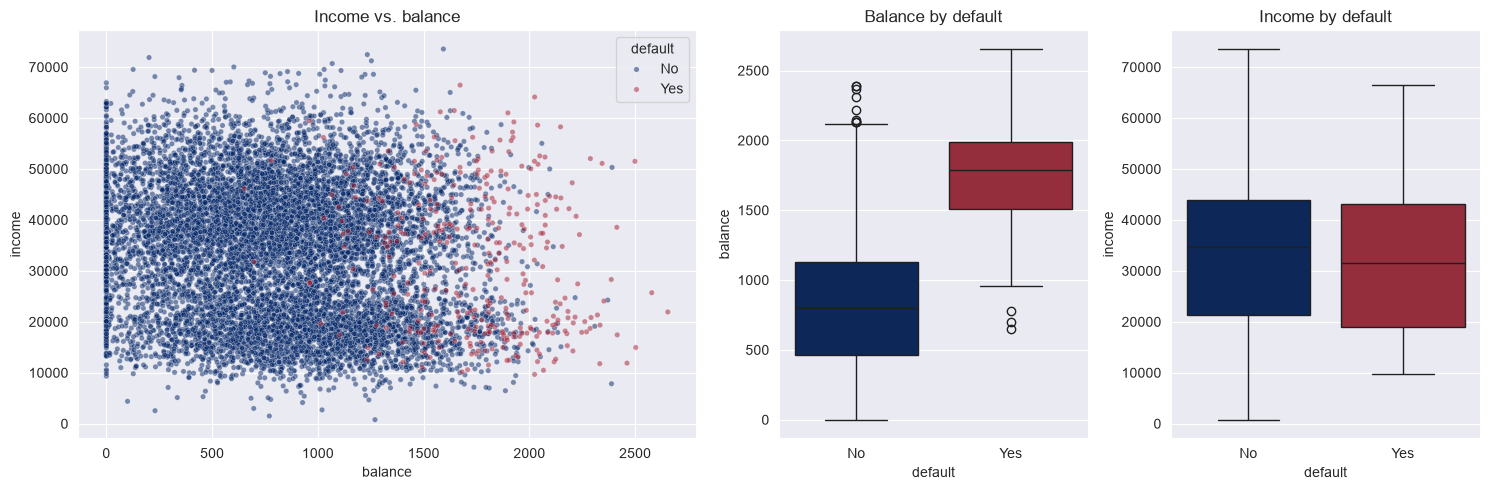

In [9]:
fig, axes = plt.subplots(
    1, 
    3, 
    figsize=(15, 5), 
    gridspec_kw={'width_ratios': [2, 1, 1]}, 
)

# Panel 1: income vs. balance, colored by default status.
# Draw "No" first so the rarer "Yes" points sit on top.
sns.scatterplot(
    data=default_df.sort_values('default'), 
    x='balance', 
    y='income', 
    hue='default', 
    palette=DEFAULT_PALETTE, 
    alpha=0.5, 
    s=15, 
    ax=axes[0], 
)
axes[0].set_title('Income vs. balance')

# Panels 2 and 3: boxplots by default status
sns.boxplot(
    data=default_df, 
    x='default', 
    y='balance', 
    hue='default', 
    palette=DEFAULT_PALETTE, 
    legend=False, 
    ax=axes[1], 
)
axes[1].set_title('Balance by default')

sns.boxplot(
    data=default_df, 
    x='default', 
    y='income', 
    hue='default', 
    palette=DEFAULT_PALETTE, 
    legend=False, 
    ax=axes[2], 
)
axes[2].set_title('Income by default')

plt.tight_layout()
plt.show()

**What the plots say:**
- **Balance** separates the two groups clearly. Customers who defaulted carry
  much higher balances (median around \$1,800 vs. \$800), and the crimson
  points crowd the right side of the scatter.
- **Income** barely differs between the groups: the two boxes overlap almost
  entirely.

So `balance` is the natural first predictor.

# Train / test split

Hold out 20% of the customers to test the model on data it has not seen.

`stratify=y` keeps the same share of defaults in both sets. With only ~3%
"Yes", a plain random split could leave the test set with noticeably more or
fewer defaulters than the full data.

Double brackets, `default_df[['balance']]`, keep `balance` as a one-column
DataFrame, the shape scikit-learn expects for X.

In [10]:
X = default_df[['balance']]
y = default_df['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    stratify=y, 
    random_state=40, 
)

In [11]:
X_train.shape, X_test.shape

((8000, 1), (2000, 1))

In [12]:
# Same share of "Yes" in both sets, thanks to stratify=y
y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)

(default
 No     0.96675
 Yes    0.03325
 Name: proportion, dtype: float64,
 default
 No     0.9665
 Yes    0.0335
 Name: proportion, dtype: float64)

# Fit the model: `default ~ balance`

`C=np.inf` turns off regularization. scikit-learn adds L2 regularization by
default (`C=1.0`; a smaller `C` means a stronger penalty). The book's model has
none, so this keeps our coefficients comparable with the book's Table 4.1.

(Older code writes `penalty=None` for the same thing. scikit-learn deprecated
that in version 1.8.)

In [13]:
balance_lgr = LogisticRegression(C=np.inf)
balance_lgr.fit(X_train, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",inf
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

## Coefficients

Compare with the book's Table 4.1, fit on all 10,000 customers:
intercept −10.6513, balance 0.0055. Ours are fit on the 80% training set, so
they are close but not identical.

The coefficient is on the **log-odds** scale: each extra dollar of balance
raises the log-odds of default by about 0.0055. Its sign is what matters most
here: positive, so a higher balance means a higher chance of default.

In [14]:
balance_lgr.intercept_, balance_lgr.coef_

(array([-10.55957392]), array([[0.00544993]]))

In [15]:
# The order of the classes: column 0 is "No", column 1 is "Yes"
balance_lgr.classes_

array(['No', 'Yes'], dtype=object)

# The S-curve

The book's Figure 4.2. Each dot is a test customer, placed at 0 (No) or 1 (Yes).
The line is the model's predicted **probability of default** at every balance.

Unlike a straight line, the S-curve never goes below 0 or above 1, so it
always reads as a probability.

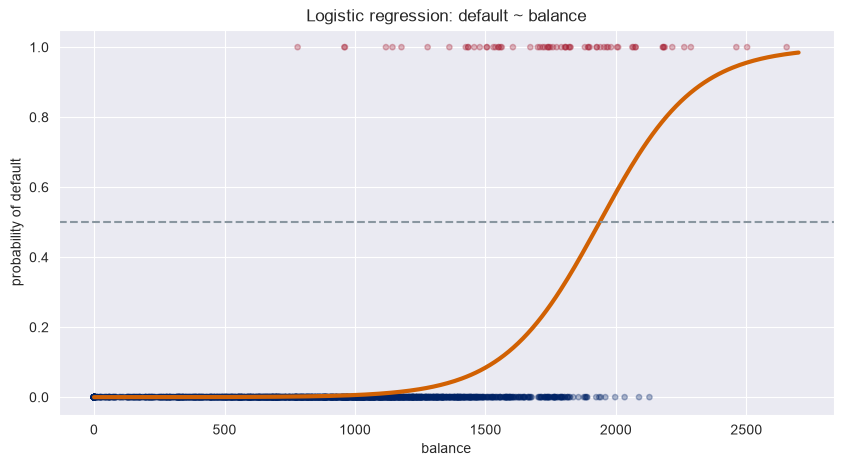

In [16]:
balance_grid = pd.DataFrame({'balance': np.linspace(0, 2700, 300)})
balance_grid_prob = balance_lgr.predict_proba(balance_grid)[:, 1]   # column 1 = P(Yes)

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    X_test['balance'], 
    (y_test == 'Yes').astype(int), 
    c=y_test.map(DEFAULT_PALETTE), 
    alpha=0.3, 
    s=15, 
)
ax.plot(balance_grid['balance'], balance_grid_prob, color=SAFFRON, linewidth=3)
ax.axhline(0.5, color=SLATE, linestyle='--')

ax.set_xlabel('balance')
ax.set_ylabel('probability of default')
ax.set_title('Logistic regression: default ~ balance')
plt.show()

# `predict_proba()` vs. `predict()`

The book's example: a customer with a \$1,000 balance vs. one with \$2,000.

`predict_proba()` returns one probability per class: [P(No), P(Yes)].

In [17]:
two_customers_df = pd.DataFrame({'balance': [1000, 2000]})
balance_lgr.predict_proba(two_customers_df)

array([[0.99399802, 0.00600198],
       [0.41574059, 0.58425941]])

`predict()` turns each probability into a Yes/No answer: "Yes" when
P(Yes) is above 0.5.

In [18]:
balance_lgr.predict(two_customers_df)

array(['No', 'Yes'], dtype=object)

## Predict the test set

In [19]:
y_predict = balance_lgr.predict(X_test)
y_predict_prob = balance_lgr.predict_proba(X_test)[:, 1]

# Actual vs. predicted for the first few test customers
pd.DataFrame(
    {
        'balance': X_test['balance'].round(0), 
        'actual': y_test, 
        'P(Yes)': y_predict_prob.round(3), 
        'predicted': y_predict, 
    }
).head(10)

,balance,actual,P(Yes),predicted
339,1222.0,No,0.020,No
2891,505.0,No,0.000,No
2828,778.0,No,0.002,No
7212,414.0,No,0.000,No
6099,276.0,No,0.000,No
9790,23.0,No,0.000,No
6620,204.0,No,0.000,No
4568,1550.0,Yes,0.108,No
3852,525.0,No,0.000,No
1887,1416.0,No,0.055,No


In [20]:
# predict() is the 0.5 threshold applied to predict_proba()
(np.where(y_predict_prob > 0.5, 'Yes', 'No') == y_predict).all()

np.True_

# Evaluate

## Accuracy

In [21]:
balance_accuracy = accuracy_score(y_test, y_predict)
balance_accuracy

0.974

## The "always say No" baseline

Before celebrating, compare with a "model" that ignores balance and always
answers "No".

In [22]:
always_no_accuracy = (y_test == 'No').mean()
always_no_accuracy

np.float64(0.9665)

97.4% accuracy sounds excellent, until you see that always saying "No" scores
96.65%. The model beats that baseline by less than one percentage point.

When one class is rare, **accuracy alone misleads**. The confusion matrix
shows where the model succeeds and where it fails.

## Confusion matrix

Rows are the actual answers, columns the model's predictions.

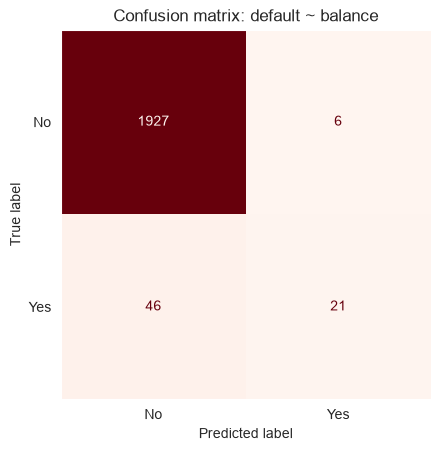

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_predict, 
    labels=['No', 'Yes'], 
    cmap='Reds', 
    colorbar=False, 
)
plt.grid(False)
plt.title('Confusion matrix: default ~ balance')
plt.show()

Reading the matrix:
- **1,927** customers who did not default were correctly predicted "No".
- **6** were flagged "Yes" but did not default: false alarms.
- **21** defaulters were caught.
- **46** defaulters were **missed**: predicted "No" but they defaulted.

Of the 67 customers in the test set who defaulted, the model caught only 21.
For a bank, those 46 misses are the expensive mistake.

## Classification report

- **Precision** (for "Yes"): of the customers the model flagged, how many
  really defaulted?
- **Recall** (for "Yes"): of the customers who really defaulted, how many did
  the model catch?

In [24]:
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

          No       0.98      1.00      0.99      1933
         Yes       0.78      0.31      0.45        67

    accuracy                           0.97      2000
   macro avg       0.88      0.66      0.72      2000
weighted avg       0.97      0.97      0.97      2000



For "Yes":
- **Precision 0.78**: when the model flags a customer, it is right about
  4 times in 5.
- **Recall 0.31**: it catches fewer than a third of the actual defaulters.

The 0.5 threshold is part of the reason. The S-curve only crosses 0.5 near a
\$2,000 balance, so many defaulters with balances around \$1,500 get
probabilities like 0.1 to 0.3 and are predicted "No". The next section lowers
the threshold.

# Choosing a threshold

0.5 is a default, not a law. The book (Section 4.4) lowers the threshold to
0.2 for this dataset: flag a customer as "Yes" whenever P(Yes) > 0.2.

The model itself does not change. Same coefficients, same probabilities; only
the cut-off that turns a probability into Yes/No moves.

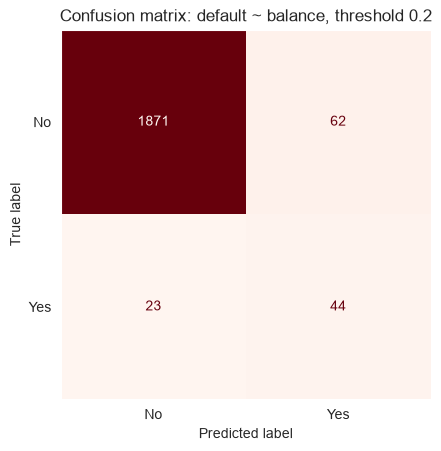

In [25]:
y_predict_20 = np.where(y_predict_prob > 0.2, 'Yes', 'No')

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_predict_20, 
    labels=['No', 'Yes'], 
    cmap='Reds', 
    colorbar=False, 
)
plt.grid(False)
plt.title('Confusion matrix: default ~ balance, threshold 0.2')
plt.show()

Compared with the 0.5 threshold:
- **44** defaulters caught, up from 21.
- **23** missed, down from 46.
- **62** false alarms, up from 6.

## Comparing thresholds

A small helper function turns a set of predictions into the counts and rates
we keep looking at, so we can line up several thresholds in one table.

In [26]:
def default_metrics(y_actual, y_predicted):
    """
    Summarize Yes/No default predictions.

    Parameters
    ----------
    y_actual    : array-like of 'Yes' / 'No' — the true answers
    y_predicted : array-like of 'Yes' / 'No' — the model's answers

    Returns
    -------
    dict with the confusion-matrix counts (caught, missed, false alarms)
    and accuracy, recall and precision for the "Yes" class.
    """
    tn, fp, fn, tp = confusion_matrix(
        y_actual, 
        y_predicted, 
        labels=['No', 'Yes'], 
    ).ravel()
    return {
        'caught': tp, 
        'missed': fn, 
        'false alarms': fp, 
        'accuracy': accuracy_score(y_actual, y_predicted), 
        'recall (Yes)': tp / (tp + fn), 
        'precision (Yes)': tp / (tp + fp), 
    }

In [27]:
# orient='index': one row per threshold (keeps the counts as whole numbers)
threshold_comparison_df = pd.DataFrame.from_dict(
    {
        threshold: default_metrics(y_test, np.where(y_predict_prob > threshold, 'Yes', 'No'))
        for threshold in [0.5, 0.2, 0.1]
    }, 
    orient='index', 
)
threshold_comparison_df.index.name = 'threshold'
threshold_comparison_df.round(3)

,caught,missed,false alarms,accuracy,recall (Yes),precision (Yes)
threshold,,,,,,
0.5,21,46,6,0.974,0.313,0.778
0.2,44,23,62,0.958,0.657,0.415
0.1,51,16,120,0.932,0.761,0.298


As the threshold drops, the model catches more defaulters (**recall** rises)
but raises more false alarms (**precision** and **accuracy** fall).

Which threshold is "best" is a business decision, not a statistical one: how
much does a missed defaulter cost the bank compared with a false alarm (say, a
good customer whose credit line gets reviewed)?

# Multiple logistic regression: `default ~ balance + income + student`

Now use all three predictors, as in the book's Section 4.3.3.

Two small preparations, both following the book:
- `student` is Yes/No text, so turn it into a number: 1 for students, 0 otherwise.
- Express `income` in thousands of dollars, the units of the book's Table 4.3.

To keep the comparison fair, reuse the **same customers** in train and test:
`X_train.index` holds the row labels the split chose. `y_train` and `y_test`
stay exactly as they were.

In [28]:
default_df['student_yes'] = (default_df['student'] == 'Yes').astype(int)
default_df['income_k'] = default_df['income'] / 1000

multi_columns = ['balance', 'income_k', 'student_yes']
X_multi_train = default_df.loc[X_train.index, multi_columns]
X_multi_test  = default_df.loc[X_test.index, multi_columns]

X_multi_train.head()

,balance,income_k,student_yes
1726,812.488298,42.721301,0
7870,0.000000,30.822454,0
8416,1305.774698,34.412116,0
3519,542.389694,14.294595,1
8363,244.662375,29.275115,0


## First, `student` on its own

Do students default more often than non-students?

In [29]:
default_df.groupby('student', observed=True)['default'].value_counts(normalize=True).unstack()

default,No,Yes
student,,
No,0.970805,0.029195
Yes,0.956861,0.043139


In [30]:
student_lgr = LogisticRegression(C=np.inf)
student_lgr.fit(X_multi_train[['student_yes']], y_train)

student_lgr.intercept_, student_lgr.coef_

(array([-3.49025444]), array([[0.36072528]]))

Students default more often (4.3% vs. 2.9%), and the coefficient is
**positive**. The book's Table 4.2, fit on all 10,000 customers, reports 0.4049;
ours, fit on the training set, is a bit smaller with the same sign.

## All three predictors

In [31]:
multi_lgr = LogisticRegression(C=np.inf)
multi_lgr.fit(X_multi_train, y_train)

pd.Series(multi_lgr.coef_[0], index=multi_columns), multi_lgr.intercept_

(balance        0.005699
 income_k       0.004571
 student_yes   -0.648269
 dtype: float64,
 array([-10.84665397]))

Compare with the book's Table 4.3: balance 0.0057, income 0.0030, 
student −0.6468.

The **student coefficient flipped sign**: positive on its own, negative once
balance and income are in the model. How can students be both riskier and
safer?

## Why the sign flips: confounding

Students carry higher balances, and higher balances drive default.

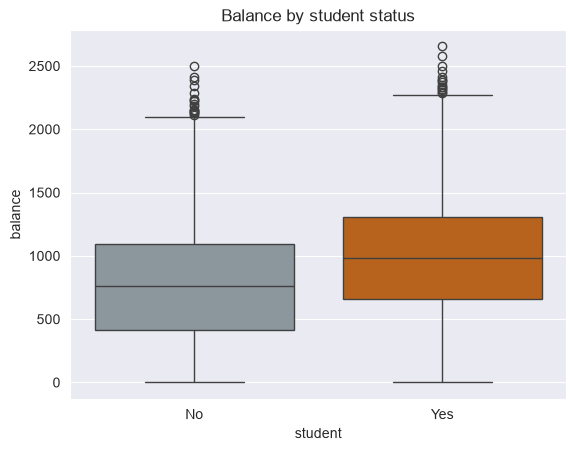

In [32]:
STUDENT_PALETTE = {'No': SLATE, 'Yes': SAFFRON}

sns.boxplot(
    data=default_df, 
    x='student', 
    y='balance', 
    hue='student', 
    palette=STUDENT_PALETTE, 
    legend=False, 
)
plt.title('Balance by student status')
plt.show()

- **On its own**, `student` picks up the effect of those higher balances, so
  students *look* riskier.
- **With balance in the model**, the comparison is between a student and a
  non-student with the *same* balance and income, and then the student is
  *less* likely to default.

The book's example: two customers with a \$1,500 balance and a \$40,000
income, one a student and one not.

In [33]:
two_customers_multi_df = pd.DataFrame(
    {
        'balance': [1500, 1500], 
        'income_k': [40, 40], 
        'student_yes': [1, 0], 
    }, 
    index=['student', 'non-student'], 
)
pd.Series(
    multi_lgr.predict_proba(two_customers_multi_df)[:, 1], 
    index=two_customers_multi_df.index, 
    name='P(Yes)', 
)

student        0.059343
non-student    0.107650
Name: P(Yes), dtype: float64

At the same balance and income, the student's probability of default is about
half the non-student's. This is **confounding**: a variable left out of the
model (balance) changes what the variable left in (student) appears to say.

For a credit card company: a student is riskier than a non-student *if
nothing else is known*, but less risky than a non-student with the same
balance.

## Does the multiple model predict better?

Same test customers, same 0.5 threshold.

In [34]:
y_multi_predict = multi_lgr.predict(X_multi_test)

pd.DataFrame.from_dict(
    {
        'default ~ balance': default_metrics(y_test, y_predict), 
        'default ~ balance + income + student': default_metrics(y_test, y_multi_predict), 
    }, 
    orient='index', 
).round(3)

,caught,missed,false alarms,accuracy,recall (Yes),precision (Yes)
default ~ balance,21,46,6,0.974,0.313,0.778
default ~ balance + income + student,23,44,6,0.975,0.343,0.793


Two more defaulters caught (23 vs. 21) and accuracy up by a tenth of a point:
practically the same predictions.

Balance does most of the work. What the multiple model adds is
**understanding**, the student effect, more than prediction. The same lesson
as the linear regression vignette: adding variables can change what the
coefficients say more than it changes the predictions.

# Summary

- Logistic regression predicts a **probability** (`predict_proba()`), and a
  threshold turns it into a class (`predict()`, 0.5 by default).
- `default ~ balance` reproduces the book's result: a positive coefficient of
  about 0.0055, so a higher balance means a higher chance of default.
- The S-curve keeps every prediction between 0 and 1.
- With a rare class (~3% defaults), **97% accuracy is barely better than always
  saying "No"**. The confusion matrix and recall reveal what accuracy hides:
  the model misses most defaulters at the 0.5 threshold.
- **The threshold is a business choice.** Lowering it from 0.5 to 0.2 doubles
  the defaulters caught, at the cost of ten times as many false alarms.
- **Confounding:** `student` looks risky on its own but lowers the risk once
  balance is in the model, because students carry higher balances.
- Adding `income` and `student` changes the *story* the coefficients tell more
  than it changes the predictions: balance does most of the work.